<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%9B%D0%912_%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Прізвище, група

# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [85]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt


In [43]:
url='https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'
html=requests.get(url, headers={'User-Agent': "mozila/5.0"}).text

tables=pd.read_html(html)
df=tables[2]
df.head()

/tmp/ipykernel_1438/2796406935.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables=pd.read_html(html)


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


In [44]:
df.columns

Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]',
       'United Nations (2024)[7]'],
      dtype='object')

2.	Визначити розмір датасета.

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222 entries, 0 to 221
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Country/Territory         222 non-null    object
 1   IMF (2026)[1]             222 non-null    object
 2   World Bank (2025)[6]      222 non-null    object
 3   United Nations (2024)[7]  222 non-null    object
dtypes: object(4)
memory usage: 7.1+ KB


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [67]:
df.columns=(df.columns
            .str.replace(r'(?:\s*\[\d+\])+', '', regex=True)
            .str.replace('Country/Territory', "Країна", regex=False)
            )
df

,Країна,IMF (2026),World Bank (2025),United Nations (2024),Difference
0,World,126295331.0,118350166.0,111565144.0,7945165.0
1,United States,32383920.0,30769700.0,29298000.0,1614220.0
2,China[n 1],20851593.0,19498039.0,18743802.0,1353554.0
3,Germany,5452858.0,5050923.0,4659929.0,401935.0
4,Japan,4379253.0,4435163.0,4026211.0,55910.0
...,...,...,...,...,...
217,Palau,377.0,345.0,310.0,32.0
218,Marshall Islands,342.0,308.0,281.0,34.0
219,Nauru,196.0,176.0,187.0,20.0
220,Montserrat,81.0,81.0,81.0,0.0


In [47]:
df=df.drop(df[df.iloc[:,0]=="world"].index)

4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [48]:
df.isnull().sum()

,0
Країна,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


In [49]:
df['IMF (2026)']=pd.to_numeric(df['IMF (2026)'], errors='coerce')
df['World Bank (2025)']=pd.to_numeric(df['World Bank (2025)'], errors='coerce')
df['United Nations (2024)']=pd.to_numeric(df['United Nations (2024)'], errors='coerce')
print(df.isnull().sum())
print(df.dtypes)

Країна                    0
IMF (2026)               31
World Bank (2025)        35
United Nations (2024)     9
dtype: int64
Країна                    object
IMF (2026)               float64
World Bank (2025)        float64
United Nations (2024)    float64
dtype: object


In [50]:
df.iloc[:,1:]=df.iloc[:,1:].apply(lambda x: x.fillna(x.mean()), axis=1)

In [65]:
print(df.isnull().sum())

Країна                   0
IMF (2026)               0
World Bank (2025)        0
United Nations (2024)    0
Difference               0
dtype: int64


In [66]:
part=df.iloc[:, 1:]

row_filled=part.apply(lambda r: r.fillna(r.mean()), axis=1)
col_means=part.mean(axis=0)
df.iloc[:, 1:]=row_filled.fillna(col_means)

print(df.isnull().sum())

Країна                   0
IMF (2026)               0
World Bank (2025)        0
United Nations (2024)    0
Difference               0
dtype: int64


5. Ще раз вивести датасет

In [64]:
df.tail()

,Країна,IMF (2026),World Bank (2025),United Nations (2024),Difference
217,Palau,377.0,345.0,310.0,32.0
218,Marshall Islands,342.0,308.0,281.0,34.0
219,Nauru,196.0,176.0,187.0,20.0
220,Montserrat,81.0,81.0,81.0,0.0
221,Tuvalu,65.0,57.0,56.0,8.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [63]:
df.duplicated().sum()

np.int64(0)

7.	Вивести описову статистику датасету describe()

In [55]:
df.describe()

,IMF (2026),World Bank (2025),United Nations (2024)
count,222.00,222.00,222.00
mean,"1,181,726.34","1,106,580.27","1,043,504.67"
std,"8,847,521.89","8,297,770.30","7,830,342.36"
min,65.00,57.00,56.00
25%,"9,638.25","9,642.12","9,170.75"
50%,"50,241.50","48,359.00","43,224.50"
75%,"379,819.00","343,693.75","304,854.50"
max,"126,295,331.00","118,350,166.00","111,565,144.00"


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [60]:

diff=abs(df["IMF (2026)"]-df[ "World Bank (2025)"])
df['Difference']=diff
df

,Країна,IMF (2026),World Bank (2025),United Nations (2024),Difference
0,World,126295331.0,118350166.0,111565144.0,7945165.0
1,United States,32383920.0,30769700.0,29298000.0,1614220.0
2,China[n 1],20851593.0,19498039.0,18743802.0,1353554.0
3,Germany,5452858.0,5050923.0,4659929.0,401935.0
4,Japan,4379253.0,4435163.0,4026211.0,55910.0
...,...,...,...,...,...
217,Palau,377.0,345.0,310.0,32.0
218,Marshall Islands,342.0,308.0,281.0,34.0
219,Nauru,196.0,176.0,187.0,20.0
220,Montserrat,81.0,81.0,81.0,0.0


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [61]:
corr = df[['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']].corr()
print(corr)


                       IMF (2026)  World Bank (2025)  United Nations (2024)
IMF (2026)               1.000000           0.999985               0.999966
World Bank (2025)        0.999985           1.000000               0.999981
United Nations (2024)    0.999966           0.999981               1.000000


In [ ]:
#Ігноруючи діагональ де показана кореляція з самим собою, найбільша кореляція в IMF та World Bank.

Обчислити середнє значення за стовпцями

In [62]:
df[['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']].mean()

,0
IMF (2026),1.181726e+06
World Bank (2025),1.106580e+06
United Nations (2024),1.043505e+06


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [68]:
cols = ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']

df['Std'] = df[cols].std(axis=1)
df # найбільша варіативність в

,Країна,IMF (2026),World Bank (2025),United Nations (2024),Difference,Std
0,World,126295331.0,118350166.0,111565144.0,7945165.0,7.372704e+06
1,United States,32383920.0,30769700.0,29298000.0,1614220.0,1.543508e+06
2,China[n 1],20851593.0,19498039.0,18743802.0,1353554.0,1.068002e+06
3,Germany,5452858.0,5050923.0,4659929.0,401935.0,3.964771e+05
4,Japan,4379253.0,4435163.0,4026211.0,55910.0,2.217380e+05
...,...,...,...,...,...,...
217,Palau,377.0,345.0,310.0,32.0,3.351119e+01
218,Marshall Islands,342.0,308.0,281.0,34.0,3.056687e+01
219,Nauru,196.0,176.0,187.0,20.0,1.001665e+01
220,Montserrat,81.0,81.0,81.0,0.0,0.000000e+00


In [72]:
print(df.sort_values('Std', ascending=False)[['Країна', 'Std']].head())

           Країна           Std
0           World  7.372704e+06
1   United States  1.543508e+06
2      China[n 1]  1.068002e+06
3         Germany  3.964771e+05
5  United Kingdom  2.898838e+05


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [83]:

data = df[df['Країна'] != 'World'].set_index('Країна')

print(
    'Найвищий', data['IMF (2026)'].idxmax(),
    '. Значення max', data['IMF (2026)'].max(),
    '. Найнижчий', data['IMF (2026)'].idxmin(),
    '. Значення min', data['IMF (2026)'].min()
)

print(
    'Найвищий', data['World Bank (2025)'].idxmax(),
    '. Значення max', data['World Bank (2025)'].max(),
    '. Найнижчий', data['World Bank (2025)'].idxmin(),
    '. Значення min', data['World Bank (2025)'].min()
)

print(
    'Найвищий', data['United Nations (2024)'].idxmax(),
    '. Значення max', data['United Nations (2024)'].max(),
    '. Найнижчий', data['United Nations (2024)'].idxmin(),
    '. Значення min', data['United Nations (2024)'].min()
)

Найвищий United States . Значення max 32383920.0 . Найнижчий Tuvalu . Значення min 65.0
Найвищий United States . Значення max 30769700.0 . Найнижчий Tuvalu . Значення min 57.0
Найвищий United States . Значення max 29298000.0 . Найнижчий Tuvalu . Значення min 56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

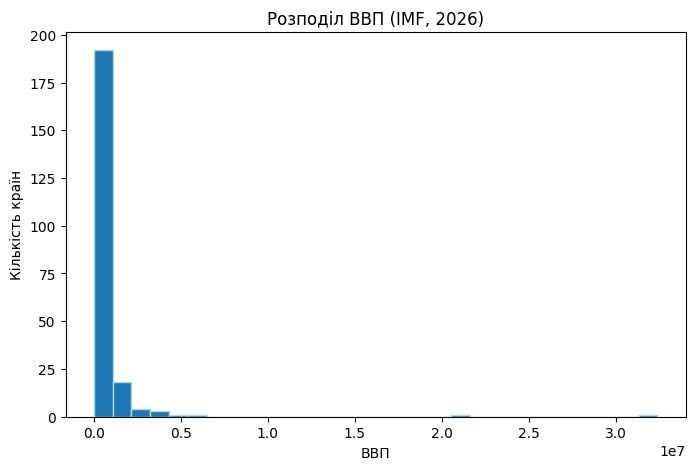

In [93]:
col = 'IMF (2026)'
values = data[col].dropna()

plt.figure(figsize=(8, 5))
plt.hist(values, bins=30, edgecolor='lightblue')
plt.title('Розподіл ВВП (IMF, 2026)')
plt.xlabel('ВВП')
plt.ylabel('Кількість країн')
plt.show()

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [97]:
cols = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']


shares = data[cols] / data[cols].sum() * 100

print(shares.round(4).sort_values('IMF (2026)', ascending=False))



                  United Nations (2024)  World Bank (2025)  IMF (2026)
Країна                                                                
United States                   24.3961            24.1690     23.8033
China[n 1]                      15.6078            15.3153     15.3267
Germany                          3.8803             3.9674      4.0080
Japan                            3.3526             3.4837      3.2189
United Kingdom                   3.0692             3.1440      3.1348
...                                 ...                ...         ...
Palau                            0.0003             0.0003      0.0003
Marshall Islands                 0.0002             0.0002      0.0003
Nauru                            0.0002             0.0001      0.0001
Montserrat                       0.0001             0.0001      0.0001
Tuvalu                           0.0000             0.0000      0.0000

[221 rows x 3 columns]


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

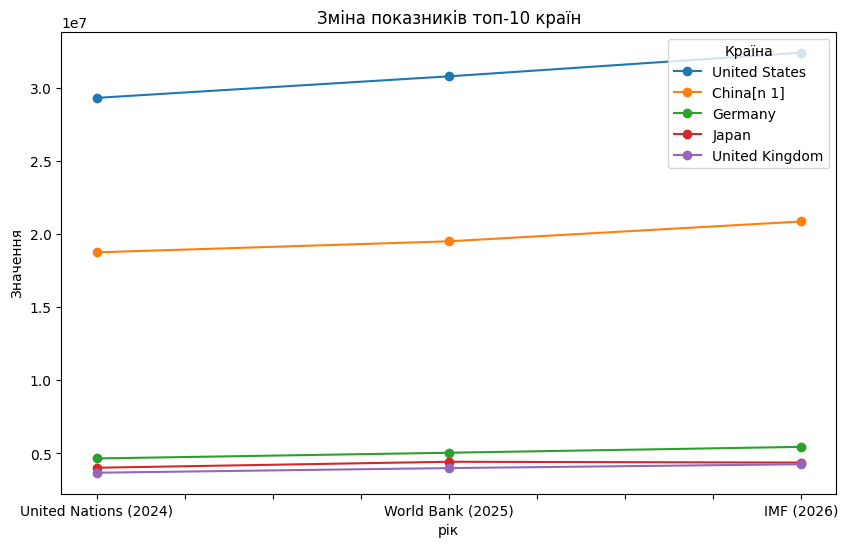

In [102]:
cols = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']

top = data[cols].sort_values('IMF (2026)', ascending=False).head(5)

top.T.plot(marker='o', figsize=(10, 6))
plt.title('Зміна показників топ-10 країн')
plt.xlabel('рік')
plt.ylabel('Значення')
plt.show() #В середньому усі країни показують зростання, хоча в деяких роках можливі тимчасові провали порівняно з попередінм роком